# PSI-117 walkthrough: cool-flame droplet data

**Investigation:** NASA PSI-117, *Effect of External Thermo-Convective Perturbation on Cool Flame Dynamics* (ground investigation re-using FLEX flight data from the ISS).

This notebook walks through every step of the workflow: load → check → clean → analyse → plot. All logic lives in `src/psi117/`; the notebook only calls it, so the same results come from `scripts/run_pipeline.py`.

| Module | Job |
|---|---|
| `config.py` | paths, file names, **corrected test conditions**, thresholds |
| `io.py` | one loader per raw file; reshapes, never changes values |
| `clean.py` | cleaning rules + the data-quality issue log |
| `analysis.py` | stages, oscillations, burning rates, extinction, pressure fits |
| `plots.py` | figures (experiment = markers, model = lines) |
| `pipeline.py` | runs everything and writes `data/processed/` and `reports/` |

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, Markdown, display
from psi117 import analysis as A, clean, config, io, plots
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

## 1. What is in the investigation

The ReadMe workbook lists 9 data files. Six were uploaded; three (`MST_2024_*` burning history, extinction diameter and radiance) were not. The table below is the **corrected** catalog: the ReadMe gives N₂ for the n-heptane rows in percent and labels ozone as 'Balance'; the dissertation (ch. 7) states 5% O₃ with balance N₂.

In [2]:
display(io.load_readme())
cleaned, issues = clean.clean_all()
cleaned["catalog"][["dataset_id", "available", "source_type", "fuel", "d0_mm", "pressure_atm",
                    "x_o2", "x_n2", "x_he", "x_o3", "doi", "figure"]]

,Fuel,do (mm),P (atm),XO2,XN2,sixth_column_label,sixth_column_value,Data File,Reference,Figure,sheet_row
0,n-heptane,0.5,1,0.21,74.00,XO3,Balance,PROCI_2019_Stable_Cool,https://doi.org/10.1016/j.proci.2018.05.151,Fig. 1,2
1,n-heptane,0.5,1,0.10,85.00,XO3,Balance,PROCI_2019_Oscillatory_Cool_Flame,https://doi.org/10.1016/j.proci.2018.05.151,Fig. 1,3
2,n-dodecane,4.5,2.75,0.21,0.50,XHe,0.29,PROCI_C12_2019_Three_Stage,https://doi.org/10.1016/j.proci.2018.09.015,Fig. 7,6
3,"n-heptane, n-decane, n-dodecane",2.0 - 7.0,1,0.21,0.79,NaN,None,PROCI_2023_Alkane_Extinction_Diameter_1atm,https://doi.org/10.1016/j.proci.2022.07.094,Fig. 3,9
4,n-dodecane,4,0.5 - 3.0,0.21,0.79,NaN,None,PROCI_2023_C12_Extinction_Diameter_vs_pressure,https://doi.org/10.1016/j.proci.2022.07.094,Fig. 7,10
5,n-dodecane,4,1,0.21,0.79,NaN,None,MST_2024_Burning_history_Flame_diameter,https://doi.org/10.1007/s12217-024-10115-x,Fig. 1,13
6,n-dodecane,4,0.5 - 1.5,0.21,0.79,NaN,None,MST_2024_Dext,https://doi.org/10.1007/s12217-024-10115-x,Fig. 5,14
7,n-dodecane,4.5,0.5 - 5.0,0.21,0.79,NaN,None,MST_2024_Kavg,https://doi.org/10.1007/s12217-024-10115-x,Fig. 4,15
8,n-dodecane,~4.5,0.5 and 5.0,0.21,0.79,NaN,None,MST_2024_Radiance_Flame_Diameter,https://doi.org/10.1007/s12217-024-10115-x,Fig. 11,16


,dataset_id,available,source_type,fuel,d0_mm,pressure_atm,x_o2,x_n2,x_he,x_o3,doi,figure
0,heptane_stable,True,simulation,n-heptane,0.5,1.0,0.21,0.74,0.00,0.05,10.1016/j.proci.2018.05.151,Fig. 1
1,heptane_oscillatory,True,simulation,n-heptane,0.5,1.0,0.10,0.85,0.00,0.05,10.1016/j.proci.2018.05.151,Fig. 1
2,c12_three_stage,True,experiment+simulation,n-dodecane,4.5,2.75,0.21,0.50,0.29,0.00,10.1016/j.proci.2018.09.015,Fig. 7
3,alkane_dext_1atm,True,experiment+simulation,"n-heptane, n-decane, n-dodecane",2.0-7.0,1.0,0.21,0.79,0.00,0.00,10.1016/j.proci.2022.07.094,Fig. 3
4,c12_dext_vs_p,True,experiment+simulation,n-dodecane,4.0,0.5-3.0,0.21,0.79,0.00,0.00,10.1016/j.proci.2022.07.094,Fig. 7
5,c12_kavg,True,experiment+simulation,n-dodecane,4.5,0.5-5.0,0.21,0.79,0.00,0.00,10.1007/s12217-024-10115-x,Fig. 4
6,mst_2024_burning_history_flame_diameter,False,unknown,n-dodecane,4.0,1.0,0.21,0.79,0.00,0.00,10.1007/s12217-024-10115-x,Fig. 1
7,mst_2024_dext,False,unknown,n-dodecane,4.0,0.5-1.5,0.21,0.79,0.00,0.00,10.1007/s12217-024-10115-x,Fig. 5
8,mst_2024_radiance_flame_diameter,False,unknown,n-dodecane,~4.5,0.5 and 5.0,0.21,0.79,0.00,0.00,10.1007/s12217-024-10115-x,Fig. 11


## 2. Data-quality checks

Each rule that fires leaves an entry here. Nothing is overwritten: cleaned values go into new columns with a `status` explaining why a value was set aside.

In [3]:
issues[["dataset", "severity", "check", "detail", "action"]]

,dataset,severity,check,detail,action
0,readme,high,units,"XN2 for the n-heptane rows is [74.0, 85.0] (percent) while XO2 is a fraction; the XO3 column reads 'Balance'.","Set XO3=0.05 and XN2=0.74 / 0.85 (fractions), per dissertation ch. 7: 'XO3 = 5%, balance N2'."
15,c12_three_stage,high,column labels,"Block labelled 'Dflame/Dodrop' reaches 24. As a ratio, the flame would be up to 103 mm across, wider than the 50 mm ...",Kept the original labels; quantity_interpreted = flame diameter (mm) for the first block and 'unidentified' for the ...
29,alkane_dext_1atm,high,sentinel zeros,"hot-flame extinction diameter = 0 for: C7 simulation 2.0, C7 simulation 3.0, C10 simulation 2.0, C10 simulation 3.0....",Set to NaN with a status; excluded from fits and ratios.
30,alkane_dext_1atm,high,sentinel zeros,"cool-flame extinction diameter = 0 for: C7 simulation 2.0, C7 simulation 3.0, C10 simulation 2.0, C10 simulation 3.0...",Set to NaN with a status; excluded from fits and ratios.
31,c12_dext_vs_p,high,sentinel zeros,Experimental cool-flame extinction diameter and its bounds are 0 at 3 atm (no cool flame extinction recorded; the pa...,Set to NaN with a status.
1,mst_2024_burning_history_flame_diameter,medium,missing file,'MST_2024_Burning_history_Flame_diameter' is listed in the ReadMe but was not in the upload.,Catalogued as unavailable; download from PSI-117 to include it.
2,mst_2024_dext,medium,missing file,'MST_2024_Dext' is listed in the ReadMe but was not in the upload.,Catalogued as unavailable; download from PSI-117 to include it.
3,mst_2024_radiance_flame_diameter,medium,missing file,'MST_2024_Radiance_Flame_Diameter' is listed in the ReadMe but was not in the upload.,Catalogued as unavailable; download from PSI-117 to include it.
8,heptane_stable,medium,ratio singularity,D_Tmax/D and D_OHm/D reach 186 and 3527 as D -> 0 (31 points with D/D0 < 0.1).,Masked in *_masked columns; raw values kept.
14,heptane_oscillatory,medium,ratio singularity,D_Tmax/D and D_OHm/D reach 341 and 3292 as D -> 0 (31 points with D/D0 < 0.1).,Masked in *_masked columns; raw values kept.


## 3. n-heptane, 0.5 mm, 5% ozone (simulation only)

Two cases from Alam et al. 2019 (Proc. Combust. Inst. 37): 21% O₂ (steady cool flame) and 10% O₂ (near-limit, oscillating).

In [4]:
hep = cleaned["heptane"]
display(hep[["case", "time_s", "d_mm", "k_mm2_s", "tmax_k", "d_tmax_over_d", "d_tmax_over_d_masked", "phase"]].head())
qs = A.heptane_quasi_steady(hep)
qs

,case,time_s,d_mm,k_mm2_s,tmax_k,d_tmax_over_d,d_tmax_over_d_masked,phase
0,stable,0.000000e+00,0.5,-0.032579,600.0,20.0398,20.0398,heat-up
1,stable,1.000000e-10,0.5,-0.032579,600.0,20.0398,20.0398,heat-up
2,stable,3.000000e-10,0.5,-0.032579,600.0,20.0398,20.0398,heat-up
3,stable,7.000000e-10,0.5,-0.032579,600.0,20.0398,20.0398,heat-up
4,stable,1.500000e-09,0.5,-0.032579,600.0,20.0398,20.0398,heat-up


,case,x_o2,x_o3,peak_tmax_ignition_k,t_peak_tmax_s,mean_tmax_cool_k,k_avg_mm2_s,mean_fsr,burn_time_s
0,oscillatory,0.10,0.05,1150.00,0.003660,700.394529,0.267746,10.056196,1.026380
1,stable,0.21,0.05,1152.73,0.004014,761.218145,0.348115,5.509899,0.808001


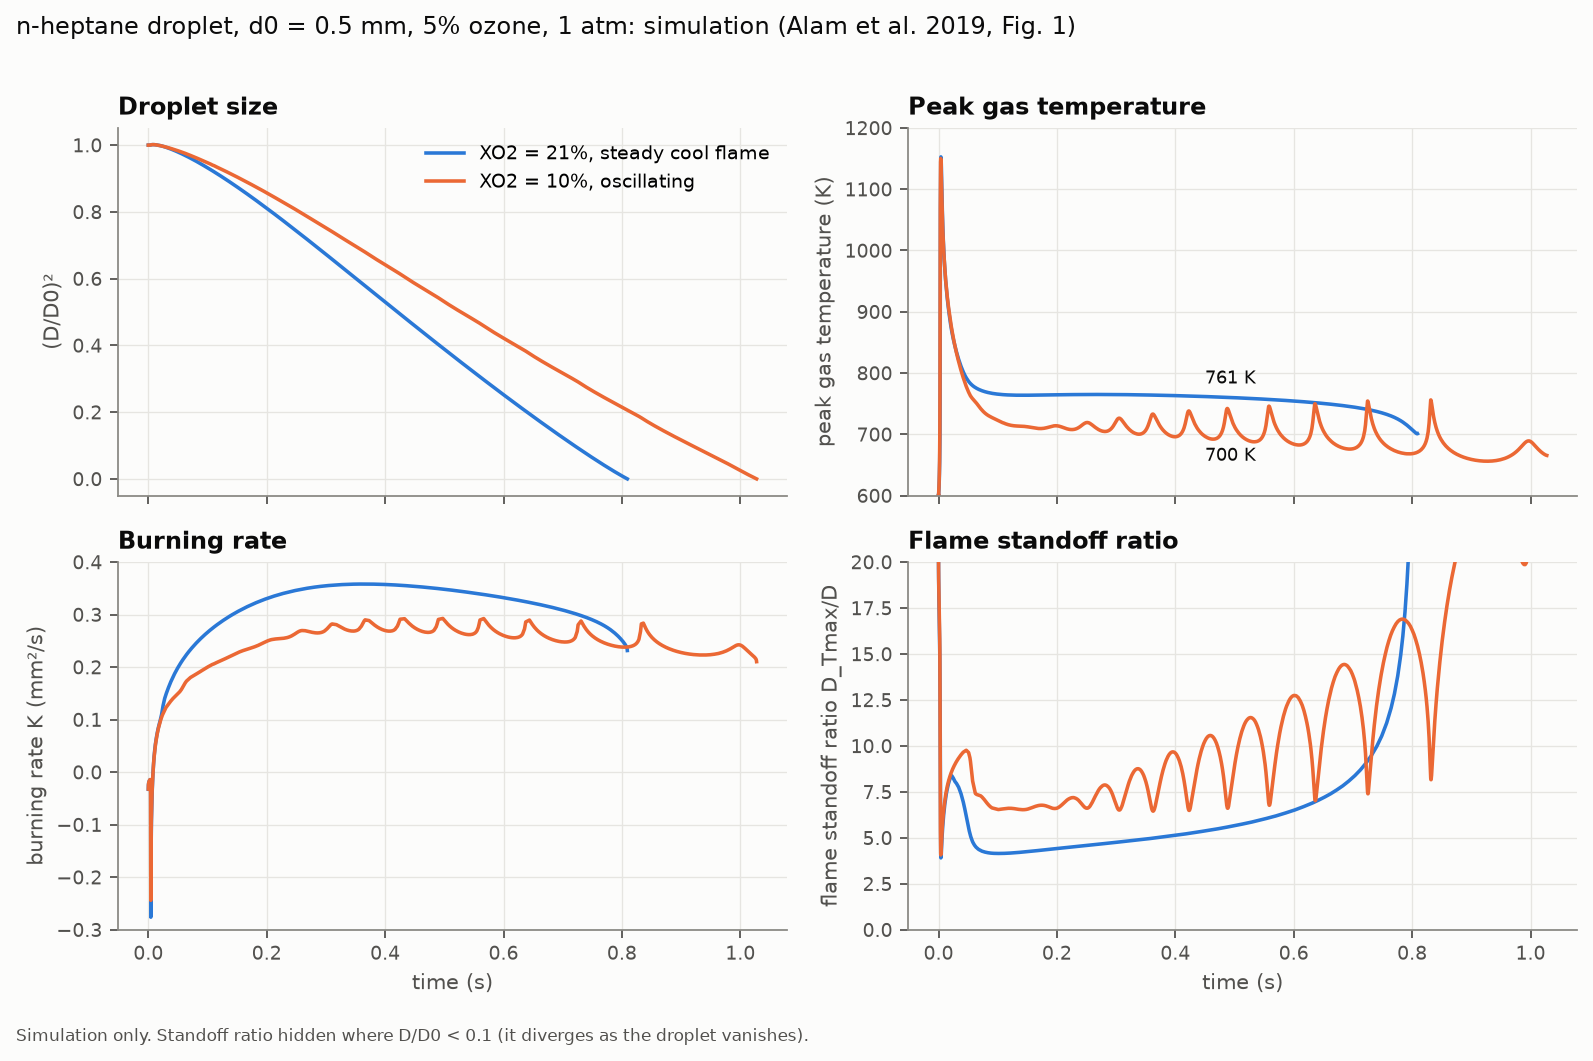

In [5]:
Image(plots.heptane_overview(hep, qs))

,value
case,oscillatory
cycles,10
first_peak_s,0.197804
last_peak_s,0.831601
period_first_s,0.053969
period_last_s,0.106694
swing_first_k,4.605
swing_last_k,88.016
prominence_growth_k_per_cycle,9.282521
prominence_growth_p,0.0


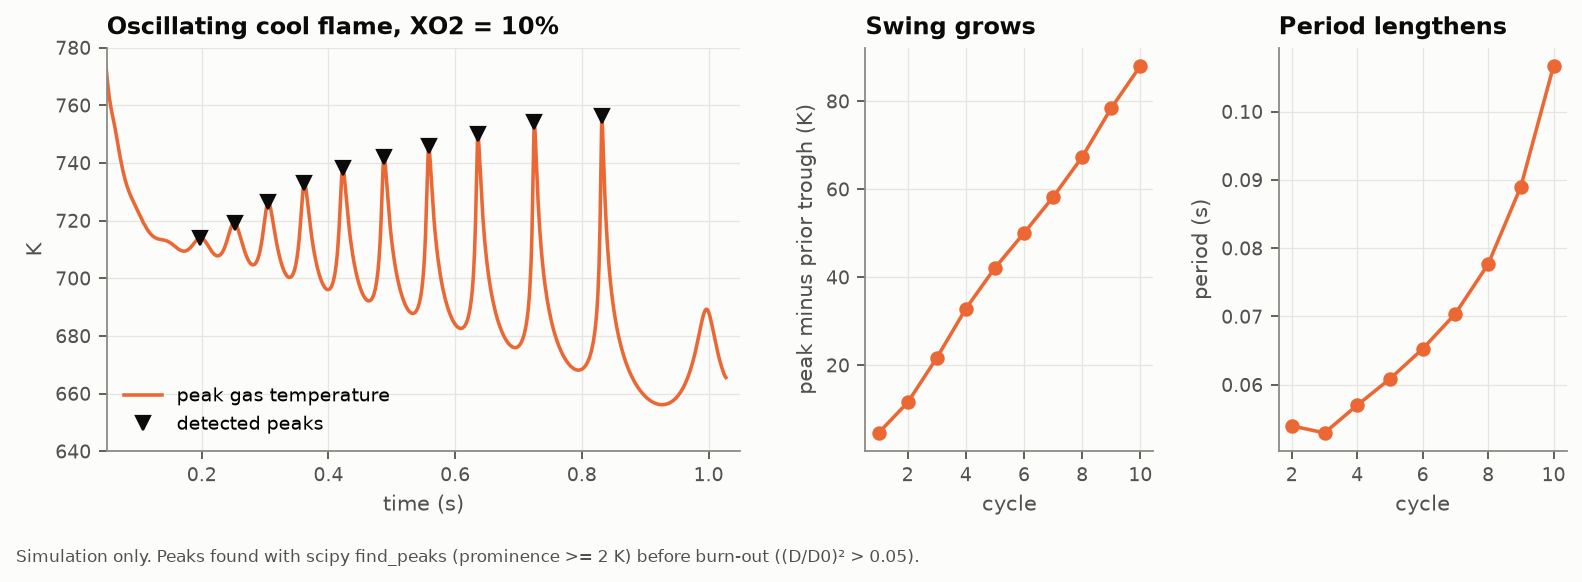

In [6]:
peaks, osc = A.heptane_oscillations(hep, "oscillatory")
display(pd.Series(osc).to_frame("value"))
Image(plots.heptane_oscillation(hep, peaks))

**Reading:** at 10% O₂ the cool flame oscillates with a swing that grows every cycle and a period that lengthens, and temperature moves opposite to the flame standoff ratio. The 21% case shows no cycles at the same threshold. Both match the authors' description.

## 4. n-dodecane three-stage burning (ISS measurement + model)

Farouk, Dietrich & Dryer 2019 (Proc. Combust. Inst. 37), Fig. 7: 2.75 atm, 21% O₂ / 29% He / 50% N₂. The file holds 7 measured curves (digitized) and 3 model blocks side by side. **Check the column-label issue in section 2** before using the flame-diameter curves.

In [7]:
ts_expt, ts_sim, ts_rad = (cleaned[k] for k in ("c12_three_stage_expt", "c12_three_stage_sim", "c12_three_stage_sim_radiance"))
display(ts_expt.groupby(["quantity_as_labelled", "quantity_interpreted", "status"]).size().to_frame("points"))
stages = A.three_stage_model_stages(ts_sim)
stages

points
quantity_as_labelled             quantity_interpreted              status                  
Dflame mm (as labelled)          unidentified (labelled Dflame mm) below_zero_noise       1
                                                                   duplicate              3
                                                                   ok                    89
Dflame/Dodrop (as labelled)      flame_diameter_mm (interpreted)   below_zero_noise       1
                                                                   duplicate              2
                                                                   ok                   134
cool_flame_diameter_fwhm         cool_flame_diameter_fwhm          duplicate             10
                                                                   not_detected           1
                                                                   ok                   107
cool_flame_diameter_peak_to_peak cool_flame_diameter_peak_to_peak  below_zero_noise       1
                                                                   duplicate             24
                                                                   not_detected          13
                                                                   ok                   120
d2_over_d02                      d2_over_d02                       duplicate              6
                                                                   ok                   199
flame_radiance_I                 flame_radiance_I                  duplicate             22
                                                                   ok                   341
flame_radiance_II                flame_radiance_II                 duplicate              7
                                                                   ok                   217

,stage,t_start_s,t_end_s,duration_s,t_over_d02_start,t_over_d02_end,mean_tmax_k,k_avg_mm2_s,d_start_mm,d_end_mm
0,hot,0.00000,6.46597,6.46597,0.000000,0.319307,1637.397491,0.289087,4.50000,4.287280
1,warm,6.48888,35.17000,28.68112,0.320439,1.736790,968.921873,0.587542,4.28605,1.232420
2,cool,35.19600,37.67330,2.47730,1.738074,1.860410,763.684660,0.605519,1.22550,0.042408


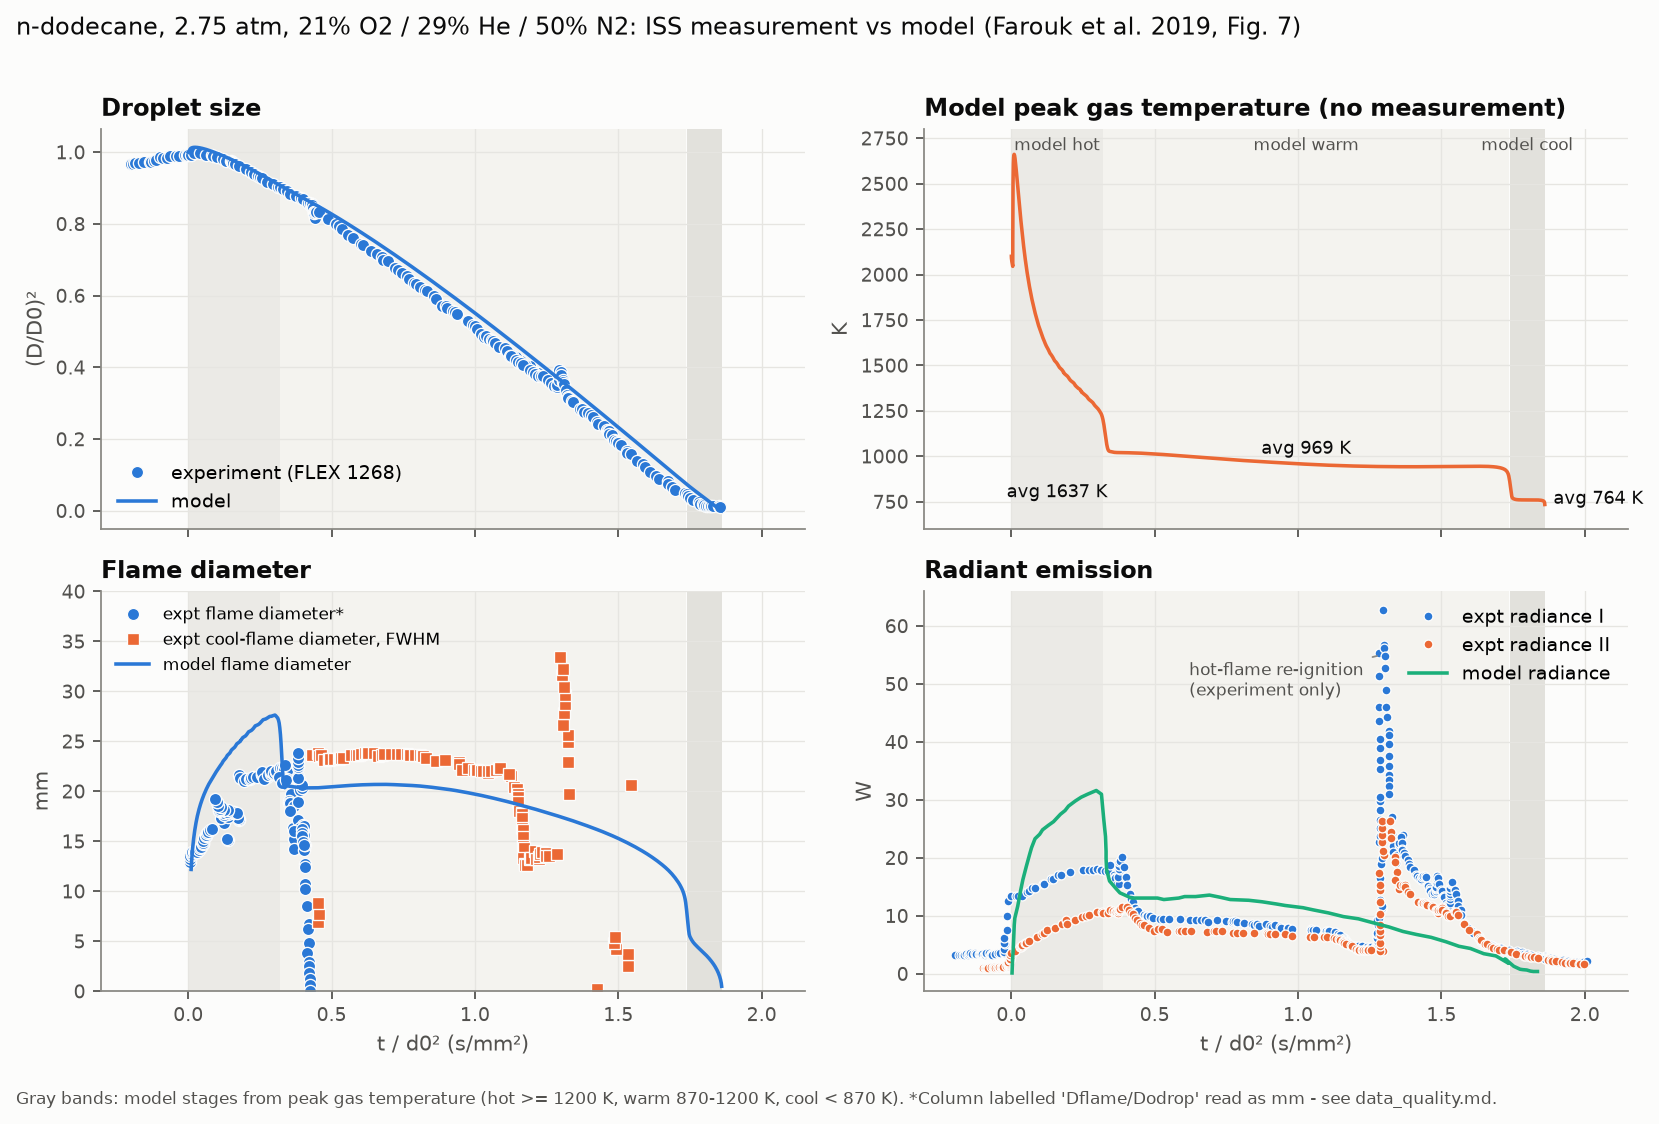

In [8]:
Image(plots.three_stage(ts_expt, ts_sim, ts_rad, stages))

,model_stage,t_over_d02_window,k_model_mm2_s,k_expt_mm2_s,expt_points
0,hot,0.00-0.32,0.289087,0.327838,23
1,warm,0.32-1.74,0.587542,0.606954,127
2,cool,1.74-1.86,0.605519,0.301513,15


{'first_cool_flame_diameter_t': np.float64(0.431562),
 'last_cool_flame_diameter_t': np.float64(1.54589),
 'last_flame_diameter_t': np.float64(0.425121),
 'last_droplet_t': np.float64(1.85565),
 'final_d2_over_d02': np.float64(0.00966184)}

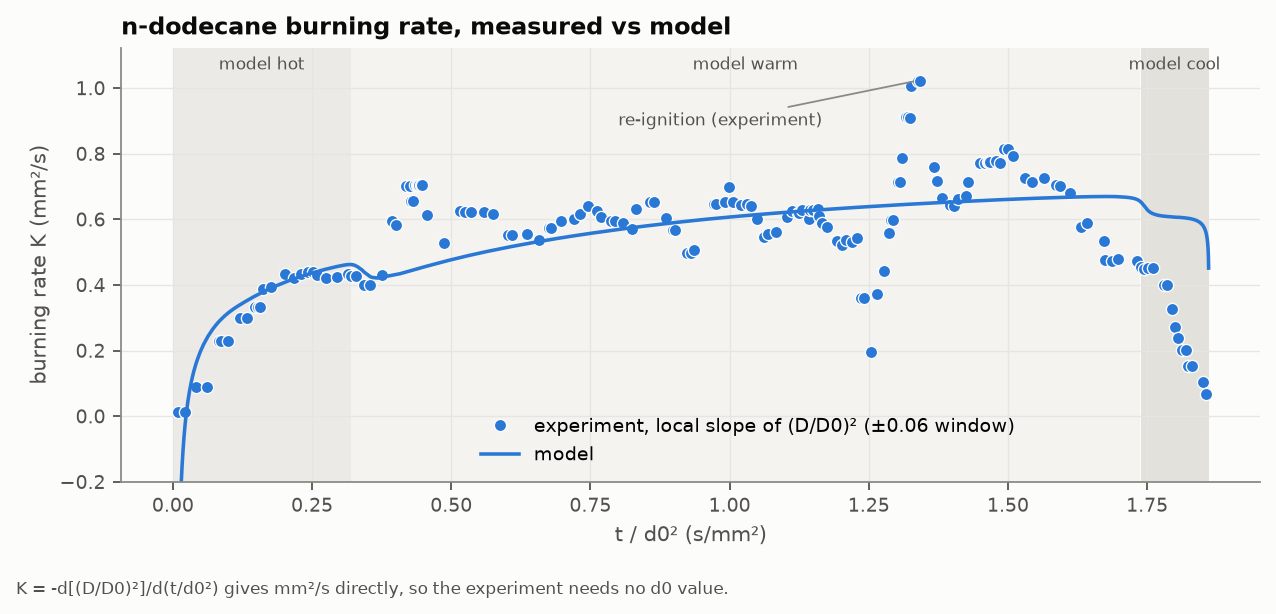

In [9]:
expt_k = A.three_stage_expt_burning_rate(ts_expt)
display(A.three_stage_compare_k(expt_k, ts_sim, stages))
display(A.three_stage_expt_markers(ts_expt))
Image(plots.three_stage_k(expt_k, ts_sim, stages))

**Reading:** droplet-size history and burning rate agree well in the hot and warm windows. Stage timing does not: the measured hot flame ends near t/d0² ≈ 0.43, the model's at 0.32, and the measured burning rate falls off well before the model's. The experiment also shows a hot-flame re-ignition near t/d0² ≈ 1.3 that the model does not predict (the paper notes the same).

## 5. Extinction diameters in air at 1 atm

Farouk & Dryer 2023 (Proc. Combust. Inst. 39), Fig. 3. A value of 0 in the file means *no extinction recorded*, not a 0 mm extinction diameter.

,fuel,source_type,cases,d0_range_mm,hot_dext_over_d0_mean,cool_dext_mm_mean,cool_dext_mm_sd,cool_dext_over_d0_mean,no_extinction_cases
0,n-heptane,experiment,5,3.34-3.91,0.796681,1.192000,0.075157,0.325764,0
1,n-heptane,simulation,6,2.00-7.00,0.952656,1.142500,0.201391,0.210375,2
2,n-decane,experiment,6,3.76-4.39,0.861733,1.045000,0.213341,0.257252,0
3,n-decane,simulation,6,2.00-7.00,0.953314,0.727500,0.235284,0.130030,2
4,n-dodecane,experiment,4,4.04-4.41,0.887224,0.448500,0.068589,0.111006,2
5,n-dodecane,simulation,6,4.04-6.00,0.946238,0.287925,0.089456,0.061619,0


,fuel,model_largest_no_extinction_d0,model_smallest_extinction_d0,expt_smallest_extinction_d0
0,n-heptane,3.0,4.000,3.342
1,n-decane,3.0,4.000,3.763
2,n-dodecane,NaN,4.039,4.039


,d0_mm,dext_hot_mm_clean_expt,dext_cool_mm_clean_expt,status_cool,dext_hot_mm_clean_model,dext_cool_mm_clean_model,hot_error_mm,cool_error_mm
0,4.408,4.059,NaN,no_extinction_recorded,4.19700,0.223160,0.13800,NaN
1,4.042,3.554,0.400,ok,3.69589,0.226994,0.14189,-0.173006
2,4.137,3.571,NaN,no_extinction_recorded,3.83030,0.288800,0.25930,NaN
3,4.039,3.577,0.497,ok,3.69188,0.218594,0.11488,-0.278406


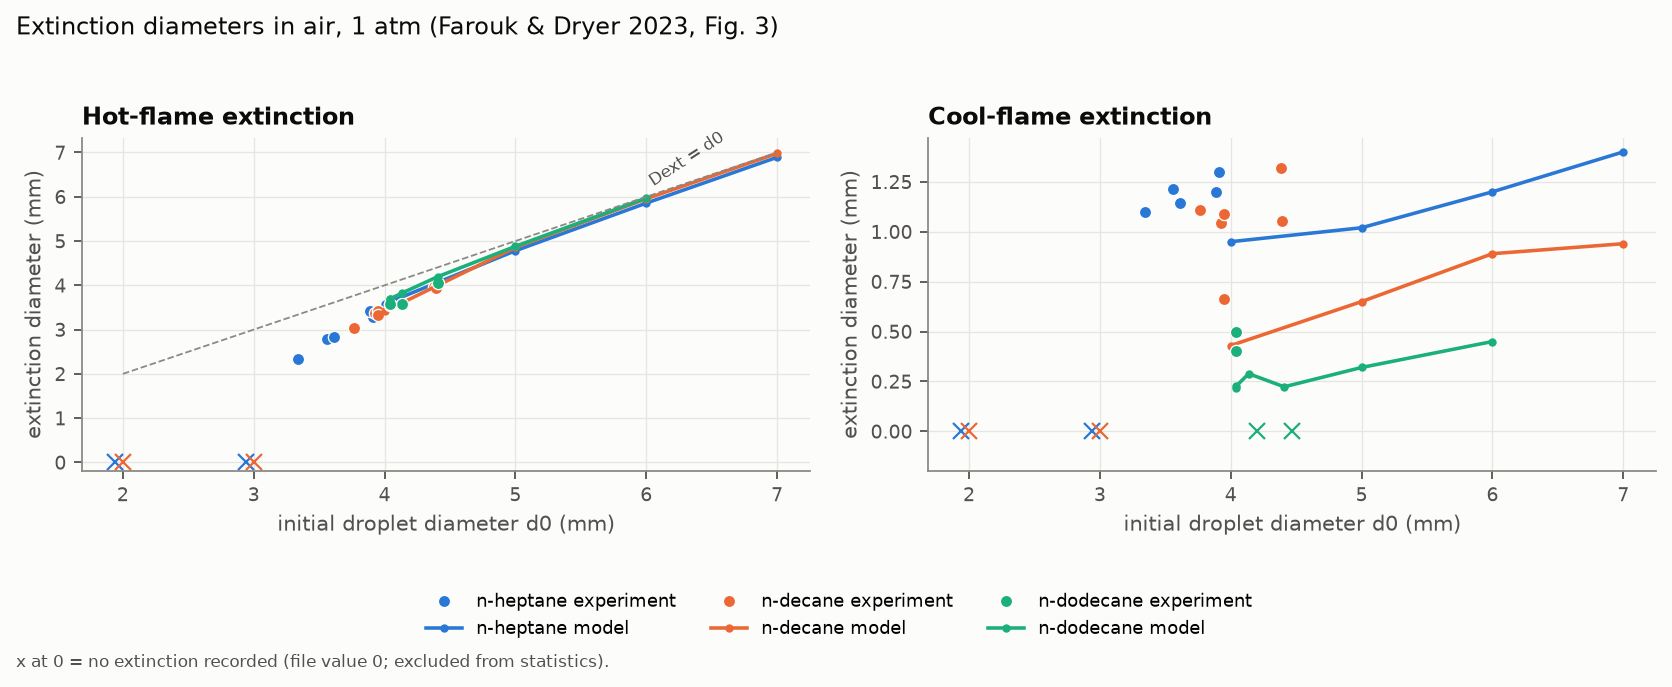

In [10]:
dx = cleaned["alkane_dext_1atm"]
display(A.extinction_summary(dx))
display(A.model_extinction_threshold(dx))
display(A.c12_matched_extinction(dx))
Image(plots.extinction_1atm(dx))

## 6. n-dodecane vs pressure

Extinction diameters (Farouk & Dryer 2023, Fig. 7) and cool-flame burning rate (Dietrich et al. 2024, Microgravity Sci. Technol., Fig. 4).

**k_fits**

,series,n,n_ci_low,n_ci_high,a,r2,points
0,"experiment, all points",0.199988,0.168118,0.231857,0.385072,0.911589,19
1,"experiment, duplicates removed",0.193451,0.162213,0.224689,0.385553,0.920731,17
2,model,0.117823,0.042816,0.192830,0.429124,0.826245,6


**k_by_pressure**

,pressure_atm,k_expt_mean,k_expt_sd,tests,k_model,model_minus_expt_pct
0,0.50,0.323169,0.009307,4,0.373960,15.716435
1,0.75,0.369274,NaN,1,0.407800,10.432942
2,1.00,0.389652,0.016511,5,0.447921,14.953997
3,1.25,0.418749,0.014800,4,0.471388,12.570373
4,2.00,0.457208,NaN,1,NaN,NaN
5,3.00,0.469240,0.034122,2,0.486890,3.761486
6,5.00,0.514530,0.018088,2,0.501200,-2.590724


**dext_by_pressure**

,pressure_atm,dext_cool_experiment,dext_cool_simulation,dext_cool_bound_lower_experiment,dext_cool_bound_upper_experiment,dext_hot_experiment,dext_hot_simulation
0,0.50,1.890,1.19,0.66,2.29,3.48,3.43
1,0.75,0.490,0.41,0.23,0.81,3.57,3.69
2,1.00,0.435,0.25,0.15,0.67,3.56,3.68
3,1.25,0.380,0.33,0.14,0.58,3.62,3.74
4,3.00,NaN,0.03,NaN,NaN,3.56,3.94


**dext_spearman**

,spearman_rho_vs_pressure
dext_cool_experiment,-1.000000
dext_cool_simulation,-0.900000
dext_cool_bound_lower_experiment,-1.000000
dext_cool_bound_upper_experiment,-1.000000
dext_hot_experiment,0.410391
dext_hot_simulation,0.900000


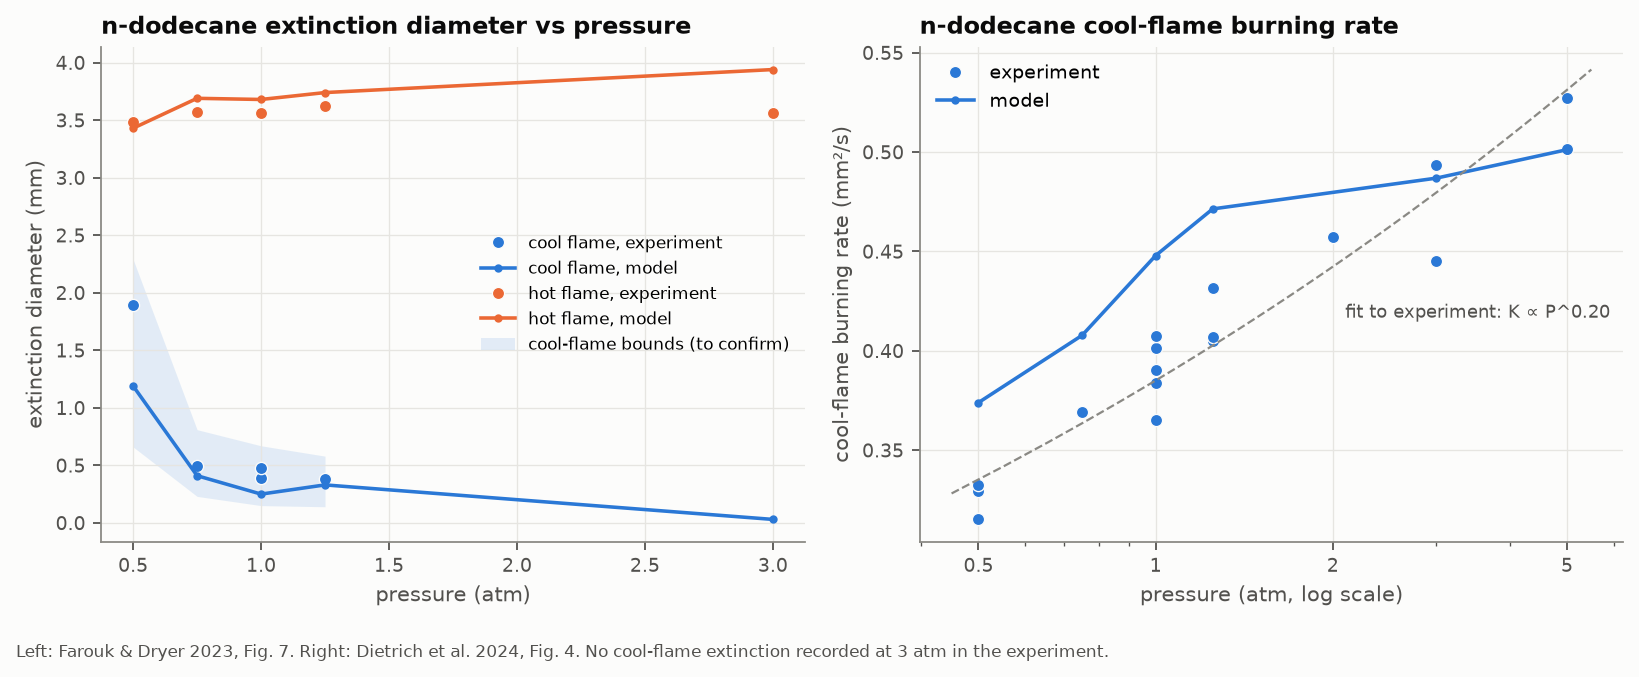

In [11]:
pt = A.pressure_trends(cleaned["c12_dext_vs_p"], cleaned["c12_kavg"])
for k, v in pt.items():
    display(Markdown(f"**{k}**")); display(v)
Image(plots.pressure(cleaned["c12_dext_vs_p"], cleaned["c12_kavg"], pt["k_fits"]))

## 7. One long table for the dashboard

`data/processed/psi117_tidy_long.csv` holds every value as one row with its conditions, its provenance (`source_type`, `source_file`, `source_line`) and its status. This is the table to load into a search/compare dashboard or a RAG index.

In [12]:
from psi117.pipeline import tidy_long
long = tidy_long(cleaned)
display(long.sample(5, random_state=1))
long.groupby(["dataset_id", "source_type", "quantity"]).size().to_frame("rows")

,dataset_id,source_type,case,fuel,quantity,unit,value,x_name,x_value,x_unit,...,pressure_atm_condition,x_o2,x_n2,x_he,x_o3,t_ambient_k,doi,figure,source_file,source_line
6101,c12_three_stage,simulation,NaN,n-dodecane,d2_over_d02,-,0.050155,t_over_d02_s_mm2,1.776519,s/mm2,...,2.75,0.21,0.50,0.29,0.00,298.0,10.1016/j.proci.2018.09.015,Fig. 7,PSI-117_Analyzed_Data_PROCI_C12_2019_Three_Stage.csv,516
6627,c12_three_stage,simulation,NaN,n-dodecane,burning_rate,mm2/s,0.669147,t_over_d02_s_mm2,1.658242,s/mm2,...,2.75,0.21,0.50,0.29,0.00,298.0,10.1016/j.proci.2018.09.015,Fig. 7,PSI-117_Analyzed_Data_PROCI_C12_2019_Three_Stage.csv,472
837,heptane_stable,simulation,stable,n-heptane,flame_standoff_ratio,-,4.938450,time_s,0.055727,s,...,1.0,0.21,0.74,0.00,0.05,298.0,10.1016/j.proci.2018.05.151,Fig. 1,PSI-117_Analyzed_Data_PROCI_2019_Stable_Cool.csv,110
1669,heptane_oscillatory,simulation,oscillatory,n-heptane,droplet_diameter,mm,0.227065,time_s,0.809220,s,...,1.0,0.10,0.85,0.00,0.05,298.0,10.1016/j.proci.2018.05.151,Fig. 1,PSI-117_Analyzed_Data_PROCI_2019_Oscillatory_Cool_Flame_1.csv,519
7189,c12_three_stage,simulation,NaN,n-dodecane,peak_gas_temperature,K,944.707000,t_over_d02_s_mm2,1.612835,s/mm2,...,2.75,0.21,0.50,0.29,0.00,298.0,10.1016/j.proci.2018.09.015,Fig. 7,PSI-117_Analyzed_Data_PROCI_C12_2019_Three_Stage.csv,464


rows
dataset_id          source_type quantity                               
alkane_dext_1atm    experiment  cool_extinction_diameter             13
                                hot_extinction_diameter              15
                    simulation  cool_extinction_diameter             14
                                hot_extinction_diameter              14
c12_dext_vs_p       experiment  dext_cool                             5
                                dext_cool_bound_lower                 4
                                dext_cool_bound_upper                 4
                                dext_hot                              5
                    simulation  dext_cool                             5
                                dext_hot                              5
c12_kavg            experiment  cool_flame_burning_rate              19
                    simulation  cool_flame_burning_rate               6
c12_three_stage     experiment  cool_flame_diameter_fwhm            118
                                cool_flame_diameter_peak_to_peak    158
                                d2_over_d02                         205
                                flame_diameter_mm (interpreted)     137
                                flame_radiance_I                    363
                                flame_radiance_II                   224
                                unidentified (labelled Dflame mm)    93
                    simulation  burning_rate                        570
                                d2_over_d02                         570
                                flame_diameter_mm                   570
                                flame_standoff_ratio                533
                                peak_gas_temperature                570
                                radiance                             72
heptane_oscillatory simulation  burning_rate                        640
                                droplet_diameter                    640
                                flame_standoff_ratio                609
                                oh_peak_location_over_d             608
                                peak_gas_temperature                640
heptane_stable      simulation  burning_rate                        243
                                droplet_diameter                    243
                                flame_standoff_ratio                212
                                oh_peak_location_over_d             211
                                peak_gas_temperature                243

## 8. Regenerate everything

Run `python scripts/run_pipeline.py` (or the VS Code task **2. Run the full pipeline**). It rewrites `data/processed/`, `reports/figures/`, `reports/findings.md`, `reports/data_quality.md` and `reports/data_dictionary.md`.